# Phase 3: Building the Model for Scam Text Classifier

In [18]:
# Imports
import html
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [19]:
# Load and clean the data (same cleaning as the Phase 2 notebook)
def load_data(path):
    df = pd.read_csv(path)
    df["LABEL"] = df["LABEL"].str.strip().str.lower()
    df["TEXT"] = df["TEXT"].str.replace("&lt;#&gt;", " ", regex=False).str.strip().apply(html.unescape)
    for c in ["URL", "EMAIL", "PHONE"]:
        df[c] = df[c].str.lower().eq("yes")
    return df

df = load_data("../data/Dataset_5971.csv")
print("Raw rows:", len(df))

df = df.drop_duplicates(subset="TEXT").reset_index(drop=True)
print("After removing duplicates:", len(df))

Raw rows: 5971
After removing duplicates: 5831


In [20]:
# Target: ham = 0, scam (spam + smishing) = 1
df["scam"] = (df["LABEL"] != "ham").astype(int)

counts = df["scam"].value_counts()
print(counts)
print("Share of scams:", round(counts[1] / len(df) * 100, 1), "%")

scam
0    4834
1     997
Name: count, dtype: int64
Share of scams: 17.1 %


In [21]:
# Split into training (80%) and test (20%) sets
# stratify keeps the same ham/scam mix in both sets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["scam"])

print("Training messages:", len(train_df), "| scam share:", round(train_df["scam"].mean() * 100, 1), "%")
print("Test messages:", len(test_df), "| scam share:", round(test_df["scam"].mean() * 100, 1), "%")

Training messages: 4664 | scam share: 17.1 %
Test messages: 1167 | scam share: 17.1 %


Models:

In [22]:
# Model A: TF-IDF words + Naive Bayes (baseline)
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", min_df=2, max_df=0.9)
X_train_words = tfidf.fit_transform(train_df["TEXT"])   # learn vocabulary from training only
X_test_words  = tfidf.transform(test_df["TEXT"])        # same vocabulary for test
y_train, y_test = train_df["scam"], test_df["scam"]

print("Number of word features:", X_train_words.shape[1])

nb = MultinomialNB()
nb.fit(X_train_words, y_train)
nb_pred = nb.predict(X_test_words)

print(classification_report(y_test, nb_pred, target_names=["ham", "scam"], digits=3))

Number of word features: 3465
              precision    recall  f1-score   support

         ham      0.963     0.997     0.980       967
        scam      0.982     0.815     0.891       200

    accuracy                          0.966      1167
   macro avg      0.972     0.906     0.935      1167
weighted avg      0.966     0.966     0.964      1167



In [23]:
# Model B (part 1): Phase 2 text signals as features
import sys
sys.path.append("..")
from src.scamfeatures import signal_features

S_train = signal_features(train_df["TEXT"])
S_test  = signal_features(test_df["TEXT"])
S_train.groupby(y_train.values).mean().round(2)

,word_count,digits,has_phone,has_shortcode,has_url,has_currency,caps_pct,exclaim,call_to_action,sentiment
0,14.04,0.32,0.00,0.00,0.00,0.00,5.73,0.18,0.10,0.17
1,23.00,14.84,0.56,0.43,0.21,0.27,11.32,0.61,0.76,0.45


In [24]:
# Model B (part 2): scale signals, combine with TF-IDF words, train logistic regression
from sklearn.preprocessing import StandardScaler

# Put the signals on the same scale (fit on training only)
scaler = StandardScaler()
S_train_scaled = scaler.fit_transform(S_train)
S_test_scaled  = scaler.transform(S_test)

# Words + signals side by side
X_train_B = hstack([X_train_words, csr_matrix(S_train_scaled)]).tocsr()
X_test_B  = hstack([X_test_words,  csr_matrix(S_test_scaled)]).tocsr()

# Model B: logistic regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_B, y_train)
lr_pred = logreg.predict(X_test_B)

print(classification_report(y_test, lr_pred, target_names=["ham", "scam"], digits=3))

              precision    recall  f1-score   support

         ham      0.981     0.996     0.988       967
        scam      0.978     0.905     0.940       200

    accuracy                          0.980      1167
   macro avg      0.980     0.950     0.964      1167
weighted avg      0.980     0.980     0.980      1167



In [25]:
# Content vs style vs combined

def fit_eval(Xtr, Xte, name):
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, y_train)
    print(name)
    print(classification_report(y_test, m.predict(Xte), target_names=["ham", "scam"], digits=3))
    return m

fit_eval(X_train_words, X_test_words, "Content: words only")
fit_eval(S_train_scaled, S_test_scaled, "Style: signals only")
best = fit_eval(X_train_B, X_test_B, "Combined")

Content: words only
              precision    recall  f1-score   support

         ham      0.974     0.989     0.981       967
        scam      0.941     0.870     0.904       200

    accuracy                          0.968      1167
   macro avg      0.957     0.929     0.942      1167
weighted avg      0.968     0.968     0.968      1167

Style: signals only
              precision    recall  f1-score   support

         ham      0.985     0.986     0.985       967
        scam      0.930     0.925     0.927       200

    accuracy                          0.975      1167
   macro avg      0.957     0.955     0.956      1167
weighted avg      0.975     0.975     0.975      1167

Combined
              precision    recall  f1-score   support

         ham      0.989     0.991     0.990       967
        scam      0.955     0.945     0.950       200

    accuracy                          0.983      1167
   macro avg      0.972     0.968     0.970      1167
weighted avg      0.983  

In [26]:
# Threshold table

probs = best.predict_proba(X_test_B)[:, 1]
for t in [0.3, 0.5, 0.7, 0.9, 0.95, 0.99]:
    pred = probs >= t
    print(t, "scams caught:", (pred & (y_test == 1)).sum(), "of", y_test.sum(),
          "| real texts flagged:", (pred & (y_test == 0)).sum())

0.3 scams caught: 191 of 200 | real texts flagged: 12
0.5 scams caught: 189 of 200 | real texts flagged: 9
0.7 scams caught: 185 of 200 | real texts flagged: 6
0.9 scams caught: 176 of 200 | real texts flagged: 2
0.95 scams caught: 173 of 200 | real texts flagged: 0
0.99 scams caught: 155 of 200 | real texts flagged: 0


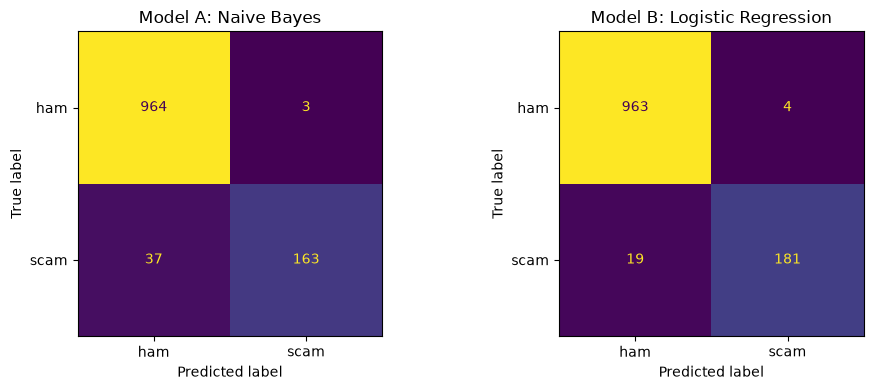

In [27]:
# Confusion matrices: where each model is right and wrong
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, display_labels=["ham", "scam"], ax=axes[0], colorbar=False)
axes[0].set_title("Model A: Naive Bayes")
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=["ham", "scam"], ax=axes[1], colorbar=False)
axes[1].set_title("Model B: Logistic Regression")
plt.tight_layout()
plt.show()

In [28]:
# Check: retrain Model B WITHOUT any phone, digit or short code information
tfidf_l = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.9, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
Xtr_l = tfidf_l.fit_transform(train_df["TEXT"])
Xte_l = tfidf_l.transform(test_df["TEXT"])
keep = [c for c in S_train.columns if c not in ("has_phone", "digits", "has_shortcode")]
sc = StandardScaler()
Xtr = hstack([Xtr_l, csr_matrix(sc.fit_transform(S_train[keep]))]).tocsr()
Xte = hstack([Xte_l, csr_matrix(sc.transform(S_test[keep]))]).tocsr()
m = fit_eval(Xtr, Xte, "No phone or digit information")

no_phone = ((test_df["scam"] == 1) & ~test_df["TEXT"].str.contains(r"\d{10,}")).values
print("Recall on scams with no phone number:", round(m.predict(Xte[no_phone]).mean(), 3))
print("Full model on the same scams:", round(best.predict(X_test_B[no_phone]).mean(), 3))

No phone or digit information
              precision    recall  f1-score   support

         ham      0.979     0.981     0.980       967
        scam      0.909     0.900     0.905       200

    accuracy                          0.967      1167
   macro avg      0.944     0.941     0.942      1167
weighted avg      0.967     0.967     0.967      1167

Recall on scams with no phone number: 0.838
Full model on the same scams: 0.862


In [29]:
# Which features push a message toward "scam" (Model B coefficients)
feature_names = list(tfidf.get_feature_names_out()) + list(S_train.columns)
coefs = pd.Series(best.coef_[0], index=feature_names)

print("Phase 2 signals (positive = more likely scam):")
print(coefs[list(S_train.columns)].sort_values(ascending=False).round(2))

print("\nTop 15 scam words:")
print(coefs.drop(S_train.columns).sort_values(ascending=False).head(15).round(2))

print("\nTop 10 ham (safe) words:")
print(coefs.drop(S_train.columns).sort_values().head(10).round(2))

Phase 2 signals (positive = more likely scam):
digits            2.42
has_url           0.94
has_phone         0.80
call_to_action    0.60
has_shortcode     0.54
has_currency      0.45
word_count        0.25
exclaim           0.14
caps_pct          0.10
sentiment         0.09
dtype: float64

Top 15 scam words:
mobile      2.65
ringtone    2.52
service     2.44
reply       2.05
tones       2.04
uk          1.93
girls       1.88
new         1.84
arsenal     1.74
shortly     1.63
order       1.57
latest      1.54
won         1.50
text        1.43
driving     1.42
dtype: float64

Top 10 ham (safe) words:
got     -1.16
day     -0.96
come    -0.92
sorry   -0.91
hey     -0.90
know    -0.89
later   -0.88
time    -0.87
ok      -0.83
da      -0.80
dtype: float64


In [30]:
# Enter any message and get the chance it's a scam (uses Model B)
def scam_test(message):
    words = tfidf.transform([message])
    signals = csr_matrix(scaler.transform(signal_features([message])))
    X = hstack([words, signals]).tocsr()
    prob = best.predict_proba(X)[0, 1]
    print(f'"{message}"\n→ {prob * 100:.1f}% chance this is a scam\n')
    return prob

In [31]:
scam_test("Hey, are we still meeting for lunch at noon?")
scam_test("URGENT! You have won a £1000 prize. Call 09061701461 now to claim. T&C apply")
scam_test("Your package could not be delivered. Update your address at usps-redelivery.com")
scam_test("Your verification code is 482913. Do not share it with anyone.")

"Hey, are we still meeting for lunch at noon?"
→ 1.2% chance this is a scam

"URGENT! You have won a £1000 prize. Call 09061701461 now to claim. T&C apply"
→ 100.0% chance this is a scam

"Your package could not be delivered. Update your address at usps-redelivery.com"
→ 83.8% chance this is a scam

"Your verification code is 482913. Do not share it with anyone."
→ 62.7% chance this is a scam



np.float64(0.626896070404747)

In [32]:
# Save the trained Model B so other notebooks can use it without retraining
import os, joblib
os.makedirs("../models", exist_ok=True)
joblib.dump({"tfidf": tfidf, "scaler": scaler, "model": best}, "../models/scam_model.joblib")
print("Saved model to models/scam_model.joblib")

Saved model to models/scam_model.joblib
